In [25]:
!pip install pyfixest[jax]

In [26]:
!pip install linearmodels

In [27]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [28]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0003
Estimator:                   PanelOLS   R-squared (Between):              0.0002
No. Observations:                6214   R-squared (Within):               0.0004
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0005
Time:                        04:45:52   Log-likelihood                -5.789e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.3137
Entities:                          29   P-value                           0.9050
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             8.0942
                            

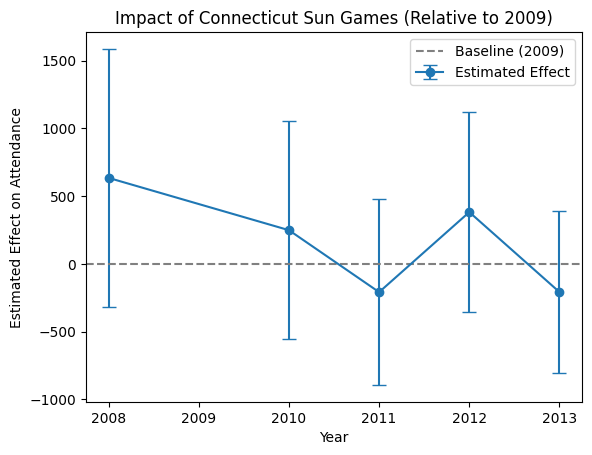

In [29]:
# Connecticut Sun (Tina Charles; 2009-2013)
ct_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Sun Games (2010-2013)
ct_attendance_df['CT_Sun_Game'] = (ct_attendance_df['Home Team'] == 'Connecticut Sun') & (ct_attendance_df['Year'].between(2008, 2013))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2009 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2008, 2010, 2011, 2012, 2013]:
    col_name = f'INX{year}'
    ct_attendance_df[col_name] = ct_attendance_df['CT_Sun_Game'].astype(int)
    ct_attendance_df.loc[ct_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ct_attendance_df = ct_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2008 + INX2010 + INX2011 + INX2012 + INX2013 + EntityEffects + TimeEffects - TimeEffects[2009]',
    ct_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2008, 2010, 2011, 2012, 2013]  # Excluding 2009 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2009)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Connecticut Sun Games (Relative to 2009)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0039
Estimator:                   PanelOLS   R-squared (Between):              0.0007
No. Observations:                6214   R-squared (Within):              -0.0058
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0007
Time:                        04:45:57   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.4220
Entities:                          29   P-value                           0.0071
Avg Obs:                       214.28   Distribution:                 F(10,6149)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             12.184
                            

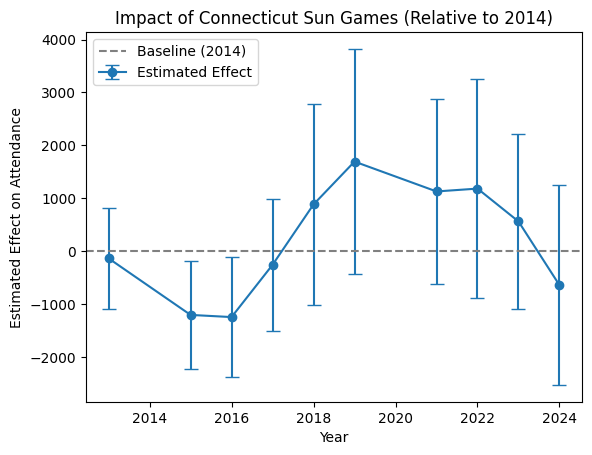

In [30]:
# Connecticut Sun (Alyssa Thomas; 2014-2024)
ct_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Sun Games (2014-2024)
ct_attendance_df['CT_Sun_Game'] = (ct_attendance_df['Home Team'] == 'Connecticut Sun') & (ct_attendance_df['Year'].between(2013, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2014 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2013, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    ct_attendance_df[col_name] = ct_attendance_df['CT_Sun_Game'].astype(int)
    ct_attendance_df.loc[ct_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ct_attendance_df = ct_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2013 + INX2015 + INX2016 + INX2017 + INX2018 + INX2019 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2014]',
    ct_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2013, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]  # Excluding 2014 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2014)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Connecticut Sun Games (Relative to 2014)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0031
Estimator:                   PanelOLS   R-squared (Between):              0.0012
No. Observations:                6214   R-squared (Within):              -0.0048
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0018
Time:                        04:46:00   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      3.1580
Entities:                          29   P-value                           0.0043
Avg Obs:                       214.28   Distribution:                  F(6,6153)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             8.0671
                            

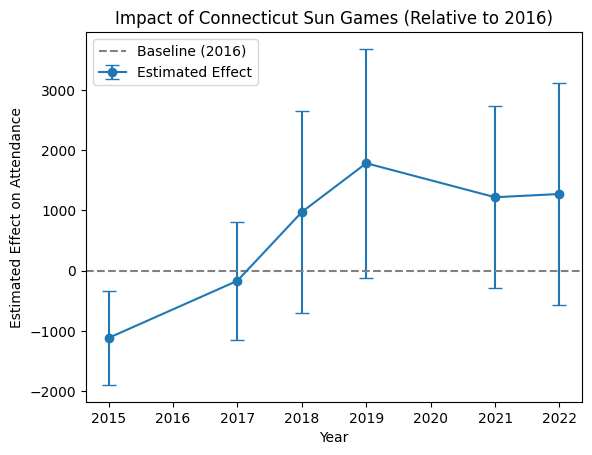

In [31]:
# Connecticut Sun (Jonquel Jones; 2016-2022)
ct_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Sun Games (2015-2022)
ct_attendance_df['CT_Sun_Game'] = (ct_attendance_df['Home Team'] == 'Connecticut Sun') & (ct_attendance_df['Year'].between(2015, 2022))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2016 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2015, 2017, 2018, 2019, 2021, 2022]:
    col_name = f'INX{year}'
    ct_attendance_df[col_name] = ct_attendance_df['CT_Sun_Game'].astype(int)
    ct_attendance_df.loc[ct_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ct_attendance_df = ct_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2015 + INX2017 + INX2018 + INX2019 + INX2021 + INX2022 + EntityEffects + TimeEffects - TimeEffects[2016]',
    ct_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2015, 2017, 2018, 2019, 2021, 2022]  # Excluding 2016 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2016)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Connecticut Sun Games (Relative to 2016)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0031
Estimator:                   PanelOLS   R-squared (Between):              0.0012
No. Observations:                6214   R-squared (Within):              -0.0050
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0019
Time:                        04:46:02   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      3.8169
Entities:                          29   P-value                           0.0019
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             11.585
                            

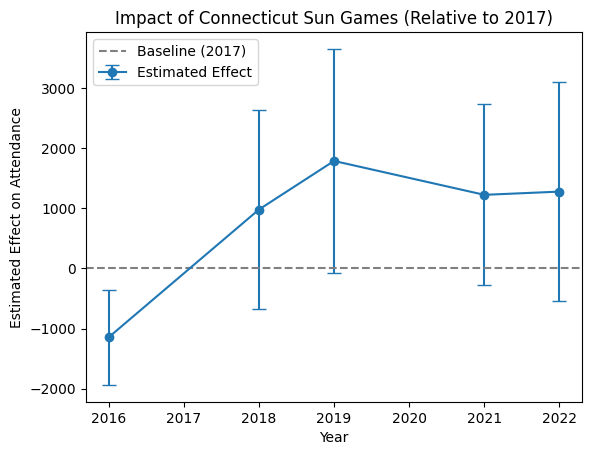

In [32]:
# Connecticut Sun (Brionna Jones; 2017-2024)
ct_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Sun Games (2016-2024)
ct_attendance_df['CT_Sun_Game'] = (ct_attendance_df['Home Team'] == 'Connecticut Sun') & (ct_attendance_df['Year'].between(2016, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2016 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2016, 2018, 2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    ct_attendance_df[col_name] = ct_attendance_df['CT_Sun_Game'].astype(int)
    ct_attendance_df.loc[ct_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ct_attendance_df = ct_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2016 + INX2018 + INX2019 + INX2021 + INX2022 + EntityEffects + TimeEffects - TimeEffects[2017]',
    ct_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2016, 2018, 2019, 2021, 2022]  # Excluding 2017 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2017)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Connecticut Sun Games (Relative to 2017)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0017
Estimator:                   PanelOLS   R-squared (Between):              0.0009
No. Observations:                6214   R-squared (Within):              -0.0058
Date:                Sat, Apr 12 2025   R-squared (Overall):              0.0012
Time:                        04:46:04   Log-likelihood                -5.789e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.0361
Entities:                          29   P-value                           0.0704
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             0.7814
                            

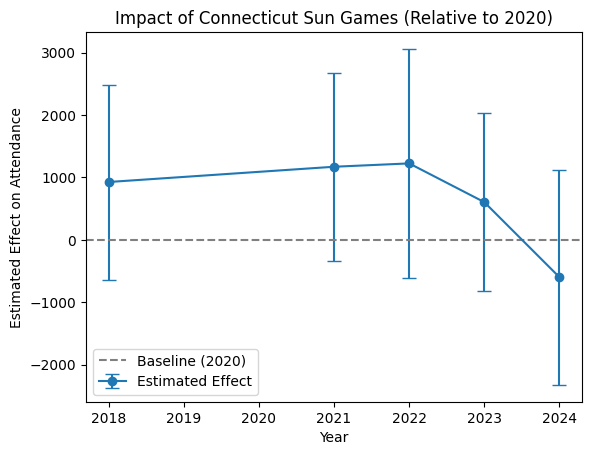

In [33]:
# Connecticut Sun (DeWanna Bonner; 2020-2024)
ct_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Sun Games (2019-2024)
ct_attendance_df['CT_Sun_Game'] = (ct_attendance_df['Home Team'] == 'Connecticut Sun') & (ct_attendance_df['Year'].between(2018, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2019 as the Reference (since there were no games in 2020)); no data for 2020 (COVID year) so I will also omit it)
for year in [2018, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    ct_attendance_df[col_name] = ct_attendance_df['CT_Sun_Game'].astype(int)
    ct_attendance_df.loc[ct_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
ct_attendance_df = ct_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2018 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2019]',
    ct_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2018, 2021, 2022, 2023, 2024]  # Excluding 2020 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2019)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Connecticut Sun Games (Relative to 2019)")
plt.legend()
plt.show()
